# Analisi modale e statistica della sala secondo la teoria di Schroeder
Il parsing dei dati `.mdat` esportati da REW avviene tramite il modulo `rew_io`.

## Costanti della stanza:

In [4]:
LX, LY, LZ = 5.70, 4.80, 2.48           # m
V  = LX * LY * LZ                        # 67.85 m^3
S  = 2 * (LX*LY + LX*LZ + LY*LZ)         # 106.8 m^2
LT = 4 * (LX + LY + LZ)                  # somma spigoli, 51.9 m
c  = 343.0                               # m/s (~20 degC)

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

from rew_io import ROOM_DIR, FIG_DIR

print(f'Dimensioni: {LX:.2f} x {LY:.2f} x {LZ:.2f} m')
print(f'Volume = {V:.2f} m^3')
print(f'Superficie = {S:.1f} m^2')
print(f'Dati salvati in: {ROOM_DIR}')

Dimensioni: 5.70 x 4.80 x 2.48 m
Volume = 67.85 m^3
Superficie = 106.8 m^2
Dati salvati in: /Users/matteob/Code/acoustics/data/room


## Parser
Estrazione dei file `.mdat`, contenente dati impacchettati da REW in formato Java. Il **parser** `rew_io` estrapola i dati di interesse dai pacchetti, per tutte le Impulse Response.
`read_mdat` riceve il percorso in cui sono salvati i dati, e restituisce un oggetto `Measurment` composto di:
- `path`: il percorso di salvataggio dati, già in input;
- `field`: tramite `parse_measdata_fields` restituisce un dizionario coi metadati della misura;
- `irs`: tramite `extract_irs` restituisce gli effettivi array di misura degli sweep effettuati su REW, con un controllo sulla lunghezza degli array stessi;

*NOTA: si può tranquillamente togliere la proprietà `room_dims` di `Measurement`, in quanto i dati dimensionali della stanza intrinseci nelle misure *.mdat* sono errati.*

In [5]:
from rew_io import read_mdat

m = read_mdat(ROOM_DIR / 'Danger_Pos1.mdat')
print(f"- Numero di sweep nel file:", len(m.irs))
print(f"- Sweep eseguito tra {m.fields['startFreq']:.1f} Hz e {m.fields['endFreq']:.1f} Hz, con risoluzione di {m.fields['freqStep']:.3f} Hz.")
print(f"- Dati acquisiti con {len(m.irs[0]):.0f} campioni, a {m.fields['sampleRate']:.0f} Hz.")

- Numero di sweep nel file: 3
- Sweep eseguito tra 20.1 Hz e 22000.1 Hz, con risoluzione di 0.366 Hz.
- Dati acquisiti con 131072 campioni, a 48000 Hz.


## Estrazione dati per le 5 posizioni
Analisi preliminare dei dati acquisiti:
- Calcolo della correlazione tra i 3 sweep come controllo sulla riproducibilità.
- SNR per ogni posizione, per attendibilità della IR.

In [6]:
import numpy as np
from rew_io import read_mdat

POSITIONS = [1, 2, 3, 4, 5]

correlations = []

print("Correlazione tra ESS in una stessa posizione.")

for pos in POSITIONS:
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    irs, mean_ir = m.irs, m.mean_ir

    # Correlazione tra gli sweep acquisiti in ciascuna posizione
    temp = []
    for i in range(len(irs)):
        for j in range(i + 1, len(irs)):
            temp.append(np.corrcoef(irs[i], irs[j])[0, 1])

    # Registro il minimo in quanto peggior caso di correlazione
    correlations.append(np.min(temp))

    print(f"Posizione {pos}: {np.min(temp):.6f}")


Correlazione tra ESS in una stessa posizione.
Posizione 1: 0.998758
Posizione 2: 0.990943
Posizione 3: 0.992562
Posizione 4: 0.990373
Posizione 5: 0.988197


## Media delle IRs
Essendo gli sweep per ogni posizione consistenti, spostiamo l'analisi sulle IR mediate, ottenendo verosimilmente un risultato più vicino al valore vero.

*NOTA: eventualmente includere il discorso dell'allineamento*

In [7]:
import numpy as np
from rew_io import read_mdat

POSITIONS = [1, 2, 3, 4, 5]

for pos in POSITIONS:
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    mean_ir, fs = m.mean_ir, m.fs

    # SNR
    noise = mean_ir[:40000] # campioni prima dell'inizio dello sweep
    signal = np.abs(mean_ir).max() # considero il massimo del segnale
    snr = 20*np.log10(signal / np.std(noise))
    print(f"Posizione {pos}: SNR = {snr:.2f} dB")

Posizione 1: SNR = 82.14 dB
Posizione 2: SNR = 78.66 dB
Posizione 3: SNR = 79.17 dB
Posizione 4: SNR = 80.12 dB
Posizione 5: SNR = 68.16 dB


## Verifica allineamento IRs
È necessario verificare che le misure, o meglio le risposte impulsive estratte dagli sweep su REW, siano allineate, in modo da avere più avanti un'unica finestra di integrazione per l'integrale di Schroeder.

In [8]:
data = []
for pos in POSITIONS:
    data.append(read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat'))

pass

## Integrale di Schröder
Il modulo `integration` incapsula i passaggi in una dataclass `BandDecay`:

1. `BandDecay.from_ir(ir, fc, fs)` — filtra la IR nella banda d'ottava (fase nulla, `sosfiltfilt`) e taglia al picco, cioè al suono diretto: è l'estremo **iniziale** di integrazione.
2. `.find_limits()` — costruzione di **Lundeby** per l'estremo **finale**: il punto in cui il decadimento incontra il rumore di fondo. Senza il troncamento la coda di rumore, essendo stazionaria, contribuisce sempre di più andando indietro nel tempo: la curva si appiattisce su un plateau e il tempo di riverberazione risulta sovrastimato.
3. `.schroeder()` — integrale all'indietro sull'energia troncata, normalizzato a 0 dB.

La curva integrata di un decadimento esponenziale è una retta in dB: tutto il contenuto fisico sta nella sua pendenza, il resto è estrapolazione. Il fit va da −5 a −25 dB (ISO 3382-1) — i primi 5 dB sono il ginocchio di suono diretto e prime riflessioni, che non appartengono al campo riverberante diffuso — e si estende a −60 dB, cioè $T_{20} = -60/\text{pendenza}$. La norma chiede inoltre che la curva scenda almeno 10 dB sotto l'estremo inferiore del fit; è una condizione da verificare a vista sui grafici della cella seguente.

Il ciclo qui sotto ripete i tre passaggi per ogni posizione microfonica e per ogni banda in `BANDS`, e scrive i $T_{20}$ nel CSV in `data/`, da cui partono le analisi a valle.

In [9]:
import numpy as np

from rew_io import ROOM_DIR, DATA_DIR, read_mdat
from integration import BandDecay

POSITIONS = [1, 2, 3, 4, 5]
BANDS = [63, 125, 250, 500, 1000, 2000, 4000] # centri delle bande d'ottava da norma ISO

DB_TOP, DB_BOT = -5.0, -25.0 # range per il fit

T20 = np.zeros((len(POSITIONS), len(BANDS)))
curve = {} # curve di Schroeder, servono per i grafici

for i, pos in enumerate(POSITIONS):
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')

    for k, fc in enumerate(BANDS):
        banda = BandDecay.from_ir(m.mean_ir, fc, m.fs).find_limits()
        curva = banda.schroeder()
        t = np.arange(len(curva)) / m.fs

        # retta fra -5 e -25 dB, estrapolata a -60 dB
        sel = (curva <= DB_TOP) & (curva >= DB_BOT)
        assert sel.sum() > 10, f'Pos{pos}, {fc} Hz: curva troppo corta per il fit'
        pendenza = np.polyfit(t[sel], curva[sel], 1)[0]

        T20[i, k] = -60 / pendenza
        curve[pos, fc] = (t, curva)

print('T20 [s]')
print(f'{"fc [Hz]":>8}' + ''.join(f'{f"Pos{p}":>7}' for p in POSITIONS) + f'{"media":>8}')
for k, fc in enumerate(BANDS):
    print(f'{fc:>8}' + ''.join(f'{T20[i, k]:>7.2f}' for i in range(len(POSITIONS)))
          + f'{T20[:, k].mean():>8.2f}')

# --- export: e' il punto di partenza delle analisi a valle ---
CSV_PATH = DATA_DIR / 't20_bande_ottava.csv'
righe = [(pos, fc, T20[i, k])
         for i, pos in enumerate(POSITIONS) for k, fc in enumerate(BANDS)]

np.savetxt(CSV_PATH, righe, delimiter=',', fmt=['%d', '%d', '%.4f'],
           header='posizione,fc_hz,T20_s', comments='')
print(f'\nScritte {len(righe)} righe in {CSV_PATH}')

T20 [s]
 fc [Hz]   Pos1   Pos2   Pos3   Pos4   Pos5   media
      63   1.48   1.08   1.06   1.31   1.11    1.21
     125   1.06   0.96   0.99   0.93   1.04    1.00
     250   0.64   0.67   0.69   0.59   0.76    0.67
     500   0.35   0.31   0.39   0.37   0.32    0.35
    1000   0.20   0.19   0.20   0.18   0.16    0.19
    2000   0.19   0.18   0.18   0.19   0.18    0.18
    4000   0.14   0.15   0.15   0.15   0.15    0.15

Scritte 35 righe in /Users/matteob/Code/acoustics/data/t20_bande_ottava.csv


## Curve di decadimento
Un subplot contiene le 5 curve filtrate per banda e integrate all'indietro, nel dominio di integrazione determinato da Lundeby. La fascia grigia è il range di fit di $T_{20}$. L'ultimo pannello raccoglie i $T_{20}(f)$.

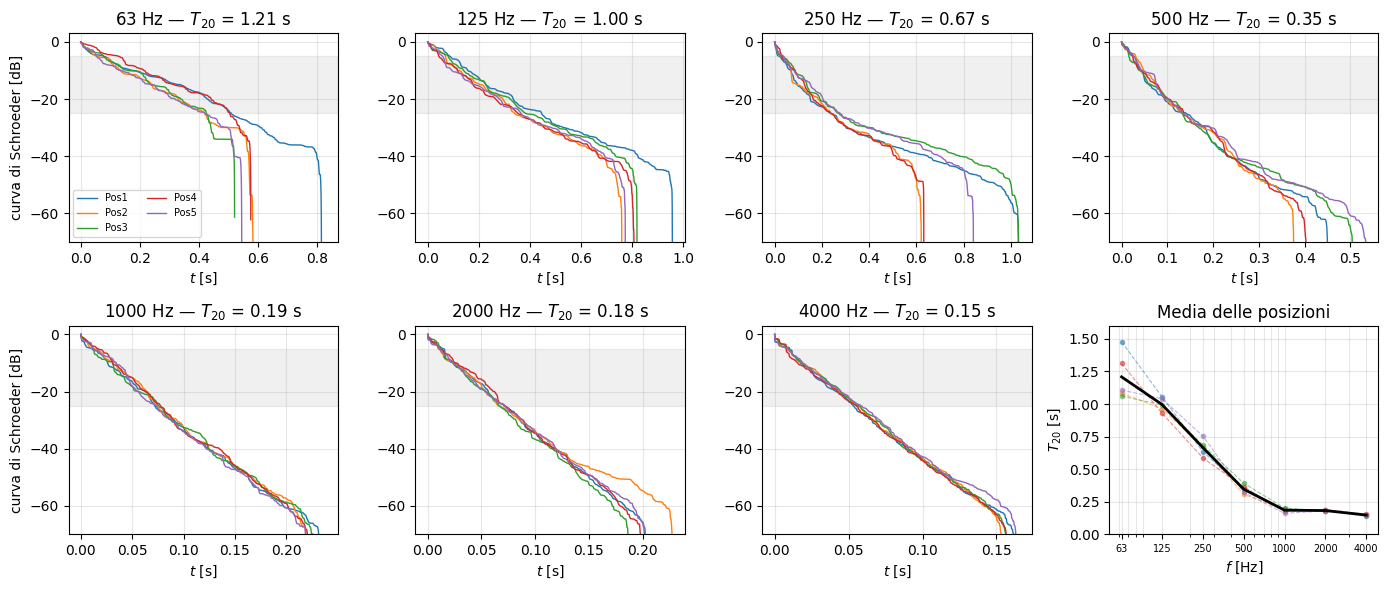

In [10]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 4, figsize=(14, 6))

for k, fc in enumerate(BANDS):
    ax = axs.flat[k]
    for pos in POSITIONS:
        t, curva = curve[pos, fc]
        ax.plot(t, curva, lw=1, label=f'Pos{pos}')
    ax.axhspan(DB_BOT, DB_TOP, color='k', alpha=0.06)      # tratto di fit
    ax.set(title=f'{fc} Hz — $T_{{20}}$ = {T20[:, k].mean():.2f} s',
           ylim=(-70, 3), xlabel=f'$t$ [s]')
    ax.grid(alpha=0.3)
axs.flat[0].set_ylabel('curva di Schroeder [dB]')
axs.flat[4].set_ylabel('curva di Schroeder [dB]')
axs.flat[0].legend(fontsize=7, ncol=2)

# ultimo pannello: T20 in funzione della frequenza
ax = axs.flat[-1]
for i in range(len(POSITIONS)):
    ax.semilogx(BANDS, T20[i], 'o--', lw=0.8, ms=3, alpha=0.5)
ax.semilogx(BANDS, T20.mean(axis=0), 'k-', lw=2, label='media 5 pos.')
ax.set(title='Media delle posizioni', xlabel=f"$f$ [Hz]", ylabel='$T_{20}$ [s]', ylim=(0, 1.6))
ax.set_xticks(BANDS, [str(b) for b in BANDS], fontsize=7)
# ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

fig.tight_layout()
fig.savefig(FIG_DIR / 'curve_schroeder_per_banda.png', dpi=200)
plt.show()

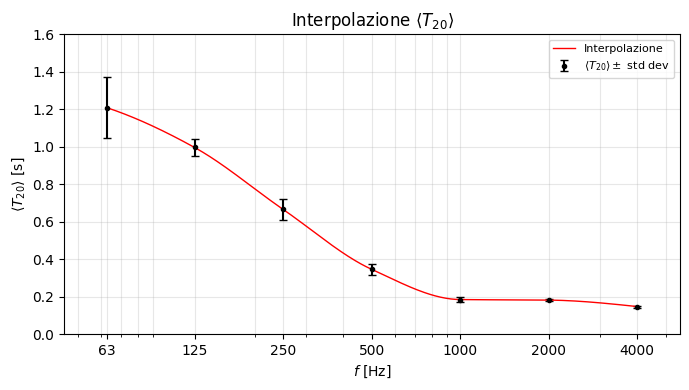

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

T20_media = T20.mean(axis=0)
T20_std = T20.std(axis=0)    # radice della varianza: stessa unita' di misura di T20 [s]

interpolazione = PchipInterpolator(np.log10(BANDS), T20_media)
f_fine = np.logspace(np.log10(BANDS[0]), np.log10(BANDS[-1]), 300)
T20_interp = interpolazione(np.log10(f_fine))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(BANDS, T20_media, yerr=T20_std, fmt='o', color='black', ms=3, capsize=3, label='$\\langle T_{20} \\rangle \\pm$ std dev')
ax.semilogx(f_fine, T20_interp, '-', lw=1, color='red', label='Interpolazione')

ax.set(title='Interpolazione $\\langle T_{20} \\rangle$', xlabel='$f$ [Hz]', ylabel='$\\langle T_{20} \\rangle$ [s]',
       xlim=(45, 5600), ylim=(0, 1.6))
ax.set_xticks(BANDS, [str(b) for b in BANDS])
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

fig.tight_layout()
fig.savefig(FIG_DIR / 't20_interpolato.png', dpi=200)
plt.show()


## Analisi in frequenza
Trasformata di Fourier delle IR.

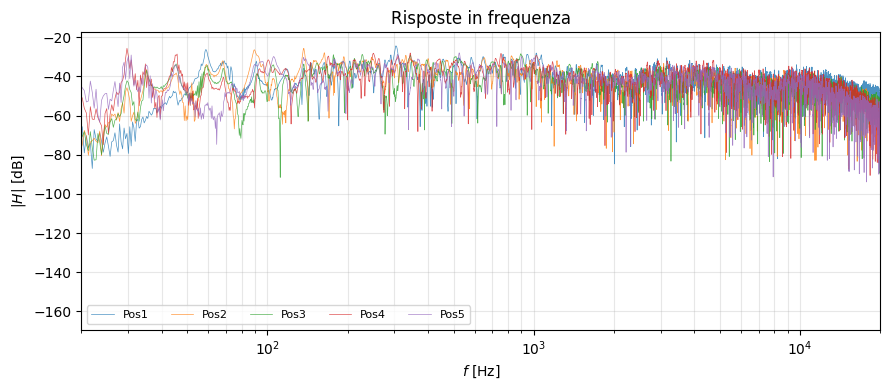

In [12]:
import numpy as np
import matplotlib.pyplot as plt

from rew_io import ROOM_DIR, DATA_DIR, CAL_DIR, read_mdat, load_rew_export
from integration import BandDecay

POSITIONS = [1,2,3,4,5]
FRs = []
FREQs = []

# File di calibrazione della catena di misura
f_mic, db_mic = load_rew_export(CAL_DIR / 'ecm8000_mic.cal')
f_sc, db_sc = load_rew_export(CAL_DIR / 'soundcard_minifuse4.cal')

for i, pos in enumerate(POSITIONS):
    measure = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    ir = measure.mean_ir
    temp_fft = np.fft.rfft(ir)
    FRs.append(20 * np.log10(np.abs(temp_fft) + 1e-30))

    nfft = len(ir)
    fs = measure.fs
    FREQs.append(np.fft.rfftfreq(nfft, 1 / fs))

    # Le tabelle di calibrazione hanno frequenze diverse da quelle della FFT:
    # le interpoliamo sulle frequenze della FFT e sottraiamo la correzione in dB
    cal_db = np.interp(FREQs[i], f_mic, db_mic) + np.interp(FREQs[i], f_sc, db_sc)
    FRs[i] = FRs[i] - cal_db

fig, ax = plt.subplots(figsize=(9, 4))
for i, pos in enumerate(POSITIONS):
    ax.semilogx(FREQs[i], FRs[i], lw=0.5, alpha=0.8, label=f'Pos{pos}')

ax.set(xlim=(20, 20000), xlabel=r'$f$ [Hz]', ylabel=r'$|H|$ [dB]',
       title='Risposte in frequenza')
ax.legend(loc='lower left', ncol=5, fontsize=8)
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig(FIG_DIR / 'risposta_in_frequenza.png', dpi=200)
plt.show()

## Modi teorici della stanza
Per una stanza rettangolare le frequenze dei modi dipendono da triplette di interi $n_x, n_y, n_z$ non negativi.

$$f_{n_x n_y n_z} = \frac{c}{2}\sqrt{\left(\frac{n_x}{L_x}\right)^2 + \left(\frac{n_y}{L_y}\right)^2 + \left(\frac{n_z}{L_z}\right)^2}$$

Calcolo dei modi e confronto con risposta in frequenza media.

Modi non obliqui sotto 200 Hz: 55
  assiale      13
  tangenziale  42

Primi 30 modi:
  f [Hz]   (nx, ny, nz)   tipo
    30.1   (1, 0, 0)      assiale
    35.7   (0, 1, 0)      assiale
    46.7   (1, 1, 0)      tangenziale
    60.2   (2, 0, 0)      assiale
    69.2   (0, 0, 1)      assiale
    70.0   (2, 1, 0)      tangenziale
    71.5   (0, 2, 0)      assiale
    75.4   (1, 0, 1)      tangenziale
    77.5   (1, 2, 0)      tangenziale
    77.8   (0, 1, 1)      tangenziale
    90.3   (3, 0, 0)      assiale
    91.7   (2, 0, 1)      tangenziale
    93.4   (2, 2, 0)      tangenziale
    97.1   (3, 1, 0)      tangenziale
    99.4   (0, 2, 1)      tangenziale
   107.2   (0, 3, 0)      assiale
   111.3   (1, 3, 0)      tangenziale
   113.7   (3, 0, 1)      tangenziale
   115.1   (3, 2, 0)      tangenziale
   120.4   (4, 0, 0)      assiale
   122.9   (2, 3, 0)      tangenziale
   125.5   (4, 1, 0)      tangenziale
   127.6   (0, 3, 1)      tangenziale
   138.3   (0, 0, 2)      assiale
   138.

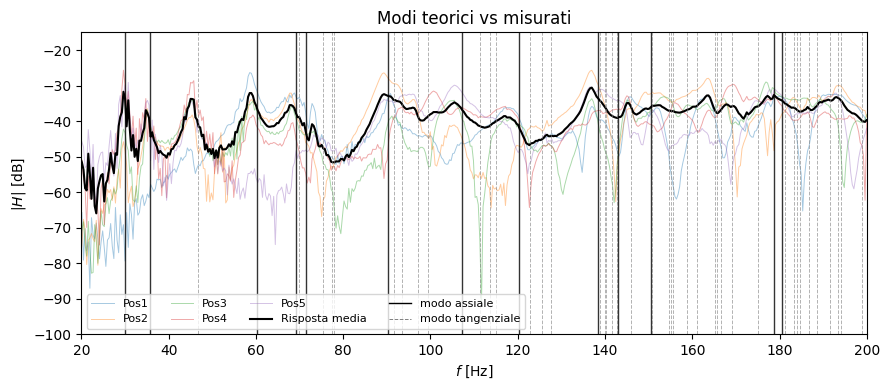

In [36]:
import numpy as np
import matplotlib.pyplot as plt

LX, LY, LZ = 5.70, 4.80, 2.48           # m
V  = LX * LY * LZ                        # 67.85 m^3
S  = 2 * (LX*LY + LX*LZ + LY*LZ)         # 106.8 m^2
LT = 4 * (LX + LY + LZ)                  # somma spigoli, 51.9 m
c  = 343.0                               # m/s (~20 degC)

F_MAX = 200    # Hz, frequenza massima dei modi da calcolare
N_MAX = int(2 * F_MAX * LX / c) + 1 # Indice massimo da provare, ottenuto invertendo n_X da f_max

modi = []

for nx in range(N_MAX + 1):
    for ny in range(N_MAX + 1):
        for nz in range(N_MAX + 1):
            if nx == 0 and ny == 0 and nz == 0:
                continue
            f = c / 2 * np.sqrt((nx / LX)**2 + (ny / LY)**2 + (nz / LZ)**2)
            if f > F_MAX:
                continue
            # il tipo dipende da quanti indici sono diversi da zero
            indici_non_nulli = (nx > 0) + (ny > 0) + (nz > 0)
            if indici_non_nulli == 1:
                tipo = 'assiale'
                modi.append((f, nx, ny, nz, tipo))
            elif indici_non_nulli == 2:
                tipo = 'tangenziale'
                modi.append((f, nx, ny, nz, tipo))
            else:
                tipo = 'obliquo'

modi.sort()    # ordina per frequenza crescente (la frequenza e' il primo elemento)

# riepilogo
print(f'Modi non obliqui sotto {F_MAX} Hz: {len(modi)}')
for tipo in ['assiale', 'tangenziale']:
    quanti = 0
    for modo in modi:
        if modo[4] == tipo:
            quanti += 1
    print(f'  {tipo:<12} {quanti}')

# tabella
N_TABELLA = 30    # quanti modi stampare
print(f'\nPrimi {N_TABELLA} modi:')
print(f'{"f [Hz]":>8}   {"(nx, ny, nz)":<14} tipo')
for f, nx, ny, nz, tipo in modi[:N_TABELLA]:
    print(f'{f:>8.1f}   {str((nx, ny, nz)):<14} {tipo}')

# media in potenza delle 5 posizioni misurate
potenze = []
for i in range(len(POSITIONS)):
    potenze.append(10 ** (FRs[i] / 10))
FR_media = 10 * np.log10(np.mean(potenze, axis=0))

# confronto con le risposte in frequenza misurate
fig, ax = plt.subplots(figsize=(9, 4))
for i, pos in enumerate(POSITIONS):
    ax.plot(FREQs[i], FRs[i], lw=0.7, alpha=0.4, label=f'Pos{pos}')
ax.plot(FREQs[0], FR_media, color='black', lw=1.5, label='Risposta media')

for f, nx, ny, nz, tipo in modi:
    if tipo == 'assiale':
        ax.axvline(f, color='black', lw=1, alpha=0.8)
    else:
        ax.axvline(f, color='gray', lw=0.7, alpha=0.6, ls='--')

ax.plot([], [], color='black', lw=1, label='modo assiale')
ax.plot([], [], color='gray', lw=0.7, ls='--', label='modo tangenziale')

ax.set(xlim=(20, F_MAX), ylim=(-100, -15), xlabel=r'$f$ [Hz]', ylabel=r'$|H|$ [dB]',
       title='Modi teorici vs misurati')
ax.legend(loc='lower left', ncol=4, fontsize=8)
#ax.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig(FIG_DIR / 'modi_teorici_vs_misura.png', dpi=200)
plt.show()